Shape of the dataset: (5975, 107)
Missing values in each column:
average_discount              330
average_time_between_sales    621
currency                       17
last_discount                 330
max_discount                  330
previous_discount_length      330
price                          17
dtype: int64
Missing values in each column after dropping price rows:
average_discount              325
average_time_between_sales    611
last_discount                 325
max_discount                  325
previous_discount_length      325
dtype: int64


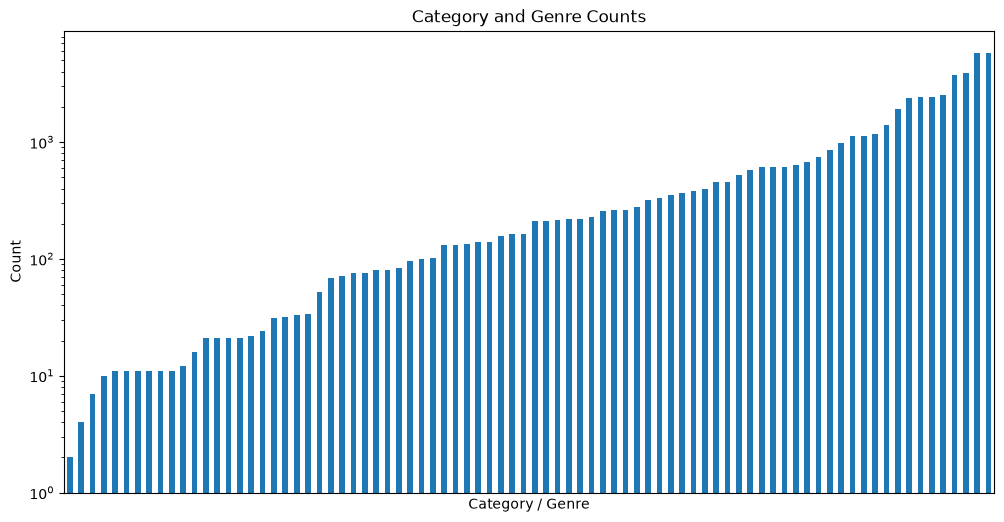

Shape of the dataset after dropping uncommon categories and genres: (5958, 75)
Unique currencies in the dataset: ['USD']
Final shape of the dataset: (5958, 73)


In [8]:
# Exploratory data analysis

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer

RANDOM_SEED = 42

df = pd.read_csv("../CreateDataset/sale_dataset.csv")

print(f"Shape of the dataset: {df.shape}")

# Check for missing values
missing_values = df.isnull().sum().sort_index()
print("Missing values in each column:")
print(missing_values[missing_values > 0])

# If a game doesn't have a price, then it can't
# go on sale currently, so we can drop those rows.
df = df.dropna(subset=["price"])

#Missing values after dropping rows that don't have a price
missing_values = df.isnull().sum().sort_index()
print("Missing values in each column after dropping price rows:")
print(missing_values[missing_values > 0])

# Next data cleaning step: remove category and genre columns that are rarely used
# If a column has a low number of "1" values, then the same size is likely to be filled with 0s, 
# which is not useful for training a model.
# For this, we will remove all category and genre columns that have less than 100 "1" values.

# Get the category and genre columns (one-hot encoded columns)
category_columns = [
    col for col in df.columns
    if col.startswith(("category_", "genre_"))
]

# # Count the occurrences of each category and genre
category_counts = df[category_columns].sum().sort_values()

plt.figure(figsize=(12, 6))
category_counts.plot(kind="bar", log=True)
plt.title("Category and Genre Counts")
plt.xlabel("Category / Genre")
plt.tick_params(axis='x', which='both', bottom=False, top=False, labelbottom=False)
plt.ylabel("Count")
plt.show()

# Simplify the list by removing uncommon genres and categories, 
# which are unlikely to be useful for training a model.
df = df.drop(columns=category_counts[category_counts < 100].index)

print(f"Shape of the dataset after dropping uncommon categories and genres: {df.shape}")

# Check to make sure currency is consistent across all rows.
print("Unique currencies in the dataset:", df["currency"].unique().tolist())

# Since every currency is USD, we can drop the currency column.
df = df.drop(columns=["currency"])

# Drop name columns, since they are not useful for training a model.
df = df.drop(columns=["name"])

print(f"Final shape of the dataset: {df.shape}")


In [ ]:
# Split the dataset into training, and testing sets

X = df.drop(columns=["target_days"])
y = df["target_days"]

# Sort the indeces of the dataset by app_id, to ensure validation and testing data
# doesn't contain any games that are in the training set.

gss = GroupShuffleSplit(n_splits=1, test_size=.20, random_state=RANDOM_SEED)

train_idx, test_idx = next(
    gss.split(X, y, groups=df["app_id"])
)


X_train = X.iloc[train_idx]
y_train = y.iloc[train_idx]
X_test = X.iloc[test_idx]
y_test = y.iloc[test_idx]

# Drop app_id column after grouping
X_train = X_train.drop(columns=["app_id"])
X_test = X_test.drop(columns=["app_id"])


print(f"Training set shape: {X_train.shape}, {y_train.shape}")
print(f"Testing set shape: {X_test.shape}, {y_test.shape}")

X_num_cols = X.drop(columns=["app_id"]).select_dtypes(include='number').columns.tolist()
# Impute numerical cols to fill missing values with the median of the column
preprocessor = ColumnTransformer(
    transformers=[
        ("num", SimpleImputer(strategy="median"), X_num_cols)
    ]
)

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)
print(f"Training set shape after imputation: {X_train.shape}")
print(f"Testing set shape after imputation: {X_test.shape}")

models = {
    "Dummy Regressor": DummyRegressor(strategy="median"),
    "Linear Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression()),
    ]),
    "Decision Tree Regressor": DecisionTreeRegressor(max_depth=6, random_state=RANDOM_SEED)
}

results = []
trained_models = {}
predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    trained_models[name] = model
    predictions[name] = {
        "train_actual": y_train,
        "train_predicted": model.predict(X_train),
        "test_actual": y_test,
        "test_predicted": model.predict(X_test),
    }

    results.append(
        {
            "model": name,
            "train_rmse": np.sqrt(mean_squared_error(y_train, y_train_pred)).round(4),
            "test_mae": round(mean_absolute_error(y_test, y_test_pred), 4),
            "test_rmse": np.sqrt(mean_squared_error(y_test, y_test_pred)).round(4),
            "test_r2": round(r2_score(y_test, y_test_pred),4),
        }
    )

results_df = pd.DataFrame(results).set_index("model")
print("Linear Regression for Charges Results:")
display(results_df)

# Plot linear regression predictions for training and testing sets
name = "Linear Regression"
train_actual = predictions[name]["train_actual"]
train_predicted = predictions[name]["train_predicted"]
test_actual = predictions[name]["test_actual"]
test_predicted = predictions[name]["test_predicted"]

Index(['app_id', 'price', 'coming_soon', 'publisher_game_count',
       'release_year', 'release_month', 'release_day',
       'category_single_player', 'category_multi_player',
       'category_shared_split_screen', 'category_steam_achievements',
       'category_full_controller_support', 'category_steam_trading_cards',
       'category_steam_cloud', 'category_steam_leaderboards',
       'category_remote_play_together', 'category_family_sharing',
       'genre_action', 'sales_since_cutoff', 'last_sale_year',
       'last_sale_month', 'last_sale_day', 'average_time_between_sales',
       'average_discount', 'max_discount', 'last_discount',
       'previous_discount_length', 'has_previous_sale',
       'category_partial_controller_support', 'genre_adventure', 'genre_indie',
       'genre_simulation', 'content_descriptor_some_nudity',
       'content_descriptor_adult_only', 'content_descriptor_general_mature',
       'content_descriptor_frequent_nudity', 'category_camera_comfort',
      

,train_rmse,test_mae,test_rmse,test_r2
model,,,,
Dummy Regressor,85.6885,33.8727,77.6407,-0.0669
Linear Regression,75.9635,34.1504,69.1014,0.1549
Decision Tree Regressor,68.0481,33.5602,75.5917,-0.0113
